# FIT5202 2026 S2 Assignment 1 : Analysing Parking & Congestion Patterns in Melbourne

## Table of Contents
* [Part 1 : Data Loading and Transformation](#part-1)  
    - [1.1 Data Preparation and Loading](#1.1)  
    - [1.2 Data Cleansing](#1.2)
    - [1.3 Partitition and Spark UI Evidence](#1.3)    
* [Part 2 : Working with DataFrames](#2-dataframes)  
    - [2.1-2.5 Query/Analysis](#2-dataframes)  
    - [2.6 Exploratory Analysis](#2.6)  
* [Part 3 : Query Optimisation](#part-3)  

Note: Feel free to add Code/Markdown cells as you need.

# Part 1 : Data Loading and Transformation (10%) <a class="anchor" name="part-1"></a>
In this section, you need to create data frames from the given datasets, perform partitioning and use various operations to answer the queries.  

## 1.1 Data Preparation and Loading <a class="anchor" name="1.1"></a>
1. Configure the Spark session to run locally using four cores;
1. Assign an appropriate application name to the Spark session;
1. Set the session timezone explicitly to 'Australia/Melbourne';
1. Define and apply an explicit StructType schema when loading each CSV and JSON dataset. 
1. Print the schema and row count for each DataFrame;
1. Display the first five rows of each DataFrame to verify successful data loading.



### 1.1.1-1.1.3 Spark Session Configuration

In [1]:
from pyspark import SparkConf
from pyspark.sql import SparkSession

# Used in app name and Spark job descriptions
student_auth_code = "ylii0798"

# 1.1.1 Run locally with 4 cores
master = "local[4]"

# 1.1.2 Application name shown in the Spark UI
app_name = f"FIT5202_A1_{student_auth_code}"

spark_conf = (
    SparkConf()
    .setMaster(master)
    .setAppName(app_name)
    # 1.1.3 Timestamps in the data are Melbourne local time
    .set("spark.sql.session.timeZone", "Australia/Melbourne")
    # Default driver memory (1g) is too small for the Part 2 joins
    .set("spark.driver.memory", "7g")
)

# Reuses the active session if one exists
spark = (
    SparkSession.builder
    .config(conf=spark_conf)
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("ERROR")

# Verify 1.1.1 - 1.1.3
print("Application Name   :", spark.conf.get("spark.app.name"))
print("Master             :", spark.conf.get("spark.master"))
print("Session TimeZone   :", spark.conf.get("spark.sql.session.timeZone"))
print("Default Parallelism:", sc.defaultParallelism)

Application Name   : FIT5202_A1_ylii0798
Master             : local[4]
Session TimeZone   : Australia/Melbourne
Default Parallelism: 4


### 1.1.4 Define schem

In [2]:
from pyspark.sql.types import (
    StructType, StructField,
    StringType, IntegerType, BooleanType, ArrayType
)

# DeviceId and time columns kept as strings to count parsing failures in 1.2
parking_schema = StructType([
    StructField("DeviceId",         StringType(),  True),
    StructField("ArrivalTime",      StringType(),  True),
    StructField("DepartureTime",    StringType(),  True),
    StructField("StreetMarker",     StringType(),  True),
    StructField("SignPlateId",      StringType(),  True),
    StructField("Sign",             StringType(),  True),
    StructField("StreetId",         IntegerType(), True),
    StructField("BetweenStreet1Id", IntegerType(), True),
    StructField("BetweenStreet2Id", StringType(),  True), 
    StructField("SideOfStreet",     IntegerType(), True),
    StructField("SideName",         StringType(),  True),
    StructField("BayId",            IntegerType(), True),
    StructField("InViolation",      BooleanType(), True),
    StructField("VehiclePresent",   BooleanType(), True),
    StructField("AreaId",           IntegerType(), True),
])

# d_minute 0-5 = 10-minute block within the hour
traffic_schema = StructType([
    StructField("d_year",        IntegerType(), True),
    StructField("d_month",       IntegerType(), True),
    StructField("d_day",         IntegerType(), True),
    StructField("d_hour",        IntegerType(), True),
    StructField("d_minute",      IntegerType(), True),
    StructField("AreaId",        IntegerType(), True),
    StructField("traffic_count", IntegerType(), True),
])

# Records are nested in an array under the "area" key
area_schema = StructType([
    StructField("area", ArrayType(
        StructType([
            StructField("areaid",   IntegerType(), True),
            StructField("areaname", StringType(),  True),
        ])
    ), True)
])

# Records are nested in an array under the "street" key
street_schema = StructType([
    StructField("street", ArrayType(
        StructType([
            StructField("streetid",   IntegerType(), True),
            StructField("streetname", StringType(),  True),
        ])
    ), True)
])

print("All schemas defined successfully.")

All schemas defined successfully.


### 1.1.4 Apply schem

In [3]:
from pyspark.sql.functions import explode, col

DATA_DIR     = "/home/student/A1/fit5202_2026_s2_dataset_v2"
PARKING_PATH = f"{DATA_DIR}/sensordata.csv"
TRAFFIC_PATH = f"{DATA_DIR}/traffic_count.csv"
AREA_PATH    = f"{DATA_DIR}/area.json"
STREET_PATH  = f"{DATA_DIR}/street.json"

# quote/escape keep quoted values with commas as one field
parking_df = (
    spark.read
    .option("header", True)
    .option("quote", '"')
    .option("escape", '"')
    .schema(parking_schema)
    .csv(PARKING_PATH)
)

traffic_df = (
    spark.read
    .option("header", True)
    .schema(traffic_schema)
    .csv(TRAFFIC_PATH)
)

# multiLine: the file is one JSON object spread over multiple lines
area_df = (
    spark.read
    .option("multiLine", True)
    .schema(area_schema)
    .json(AREA_PATH)
    # One row per record in the nested array
    .select(explode(col("area")).alias("a"))
    # Rename to match parking column names for joins in Part 2
    .select(
        col("a.areaid").alias("AreaId"),
        col("a.areaname").alias("AreaName")
    )
)

street_df = (
    spark.read
    .option("multiLine", True)
    .schema(street_schema)
    .json(STREET_PATH)
    .select(explode(col("street")).alias("s"))
    .select(
        col("s.streetid").alias("StreetId"),
        col("s.streetname").alias("StreetName")
    )
)
print("All DataFrames created with explicit schemas.")

All DataFrames created with explicit schemas.


### 1.1.5 Schema and Row Count

In [4]:
datasets = [
    ("Parking Sensor Data", parking_df),
    ("Traffic Count Data",  traffic_df),
    ("Area Lookup",         area_df),
    ("Street Lookup",       street_df),
]

for name, df in datasets:
    print(f"Dataset: {name}")
    df.printSchema()
    # count() is an action and triggers a full scan of the data
    print(f"Row count: {df.count():,}")
    print()

Dataset: Parking Sensor Data
root
 |-- DeviceId: string (nullable = true)
 |-- ArrivalTime: string (nullable = true)
 |-- DepartureTime: string (nullable = true)
 |-- StreetMarker: string (nullable = true)
 |-- SignPlateId: string (nullable = true)
 |-- Sign: string (nullable = true)
 |-- StreetId: integer (nullable = true)
 |-- BetweenStreet1Id: integer (nullable = true)
 |-- BetweenStreet2Id: string (nullable = true)
 |-- SideOfStreet: integer (nullable = true)
 |-- SideName: string (nullable = true)
 |-- BayId: integer (nullable = true)
 |-- InViolation: boolean (nullable = true)
 |-- VehiclePresent: boolean (nullable = true)
 |-- AreaId: integer (nullable = true)

Row count: 72,912,582

Dataset: Traffic Count Data
root
 |-- d_year: integer (nullable = true)
 |-- d_month: integer (nullable = true)
 |-- d_day: integer (nullable = true)
 |-- d_hour: integer (nullable = true)
 |-- d_minute: integer (nullable = true)
 |-- AreaId: integer (nullable = true)
 |-- traffic_count: integer (nu

### 1.1.6 First Five Rows

In [5]:
for name, df in datasets:
    print(f"Dataset: {name}")
    # truncate=False shows full timestamps and street names
    df.show(5, truncate=False)

Dataset: Parking Sensor Data
+--------+----------------------+----------------------+------------+-----------+----+--------+----------------+----------------+------------+--------+-----+-----------+--------------+------+
|DeviceId|ArrivalTime           |DepartureTime         |StreetMarker|SignPlateId|Sign|StreetId|BetweenStreet1Id|BetweenStreet2Id|SideOfStreet|SideName|BayId|InViolation|VehiclePresent|AreaId|
+--------+----------------------+----------------------+------------+-----------+----+--------+----------------+----------------+------------+--------+-----+-----------+--------------+------+
|17193   |10/23/2018 06:49:29 AM|10/23/2018 06:54:24 AM|13029S      |NULL       |NULL|528     |1285            |79              |4           |South   |6015 |false      |false         |35    |
|17193   |02/07/2018 07:30:00 PM|02/07/2018 07:56:23 PM|13029S      |NULL       |NULL|528     |1285            |79              |4           |South   |6015 |false      |false         |35    |
|17195   |1

### 1.2 Data Cleansing and Validation <a class="anchor" name="1.2"></a>
The following tasks must be completed to ensure data quality and consistency (feel free to add code block as you see fit):
1) Identify the missing-value representations within the dataset and convert them to null. Briefly state which values were treated as missing.


In [6]:
from pyspark.sql.functions import col, trim, upper, when, sum as _sum
from pyspark.sql.types import StringType

# Common text placeholders for missing values (compared after trim/upper)
placeholders = ["", "NA", "N/A", "NULL", "NONE", "NAN", "UNKNOWN", "-"]

def missing_profile(df):
    # Non-string columns cannot hold text; failed values already appear as null
    string_cols = [f.name for f in df.schema.fields
                   if isinstance(f.dataType, StringType)]

    # One aggregation pass so the large parking file is scanned only once
    exprs = [_sum(when(col(c).isNull(), 1).otherwise(0)).alias(f"{c}__null")
             for c in df.columns]
    exprs += [_sum(when(upper(trim(col(c))).isin(placeholders), 1)
                   .otherwise(0)).alias(f"{c}__text")
              for c in string_cols]
    row = df.agg(*exprs).collect()[0]

    rows = [(c, row[f"{c}__null"],
             row[f"{c}__text"] if c in string_cols else None)
            for c in df.columns]
    return spark.createDataFrame(
        rows, "Column string, NullCount long, TextPlaceholderCount long")

for name, df in [("Parking", parking_df), ("Traffic", traffic_df),
                 ("Area", area_df), ("Street", street_df)]:
    print(f"Dataset: {name}")
    missing_profile(df).show(truncate=False)

Dataset: Parking
+----------------+---------+--------------------+
|Column          |NullCount|TextPlaceholderCount|
+----------------+---------+--------------------+
|DeviceId        |0        |0                   |
|ArrivalTime     |0        |0                   |
|DepartureTime   |0        |0                   |
|StreetMarker    |0        |0                   |
|SignPlateId     |25195820 |0                   |
|Sign            |25195820 |0                   |
|StreetId        |0        |NULL                |
|BetweenStreet1Id|0        |NULL                |
|BetweenStreet2Id|57538    |0                   |
|SideOfStreet    |0        |NULL                |
|SideName        |0        |0                   |
|BayId           |0        |NULL                |
|InViolation     |0        |NULL                |
|VehiclePresent  |0        |NULL                |
|AreaId          |0        |NULL                |
+----------------+---------+--------------------+

Dataset: Traffic
+-------------+

In [7]:
from pyspark.sql.functions import col, trim, when, sum as _sum

# CSV reader already reads empty fields as null and no text placeholders
parking_clean = parking_df
traffic_clean = traffic_df

# JSON reader keeps "" as a string, so blank names are converted to null
area_clean = area_df.withColumn(
    "AreaName",
    when(trim(col("AreaName")) == "", None).otherwise(trim(col("AreaName")))
)

street_clean = street_df.withColumn(
    "StreetName",
    when(trim(col("StreetName")) == "", None).otherwise(trim(col("StreetName")))
)

print("Area rows with null AreaName after cleaning:")
area_clean.filter(col("AreaName").isNull()).show(truncate=False)

# Confirm traffic data has no missing values
print("Null count per column in traffic data:")
traffic_clean.select([
    _sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in traffic_clean.columns
]).show(truncate=False)

Area rows with null AreaName after cleaning:
+------+--------+
|AreaId|AreaName|
+------+--------+
|7     |NULL    |
+------+--------+

Null count per column in traffic data:
+------+-------+-----+------+--------+------+-------------+
|d_year|d_month|d_day|d_hour|d_minute|AreaId|traffic_count|
+------+-------+-----+------+--------+------+-------------+
|0     |0      |0    |0     |0       |0     |0            |
+------+-------+-----+------+--------+------+-------------+



**Missing values identified**

All string columns were checked for nulls and common text placeholders
("", "NA", "N/A", "NULL", "NONE", "NAN", "UNKNOWN", "-").

- **Parking:** no text placeholders were found. Missing values appear only as
  empty CSV fields, which Spark already reads as null: `SignPlateId` and
  `Sign` (25,195,820 each) and `BetweenStreet2Id` (57,538). No conversion
  was needed.
- **Traffic:** no missing values in any column.
- **Area:** one empty-string `AreaName` (AreaId 7) was treated as missing and
  converted to null.
- **Street:** no missing values; blank names are still converted to null for
  consistency with the area lookup.

2) Parse the 'ArrivalTime' and 'DepartureTime' columns and convert them to timestamp format. 

In [8]:
from pyspark.sql.functions import try_to_timestamp, lit

# hh = 12-hour clock with AM/PM (a); HH would conflict with the AM/PM marker
TS_FORMAT = "MM/dd/yyyy hh:mm:ss a"

# Original strings kept as *Raw so parsing failures can be counted in 1.2.8
parking_clean = (
    parking_clean
    .withColumnRenamed("ArrivalTime",   "ArrivalTimeRaw")
    .withColumnRenamed("DepartureTime", "DepartureTimeRaw")
    .withColumn("ArrivalTime",
                try_to_timestamp(col("ArrivalTimeRaw"), lit(TS_FORMAT)))
    .withColumn("DepartureTime",
                try_to_timestamp(col("DepartureTimeRaw"), lit(TS_FORMAT)))
)

parking_clean.select("ArrivalTimeRaw", "ArrivalTime",
                     "DepartureTimeRaw", "DepartureTime").show(5, truncate=False)

+----------------------+-------------------+----------------------+-------------------+
|ArrivalTimeRaw        |ArrivalTime        |DepartureTimeRaw      |DepartureTime      |
+----------------------+-------------------+----------------------+-------------------+
|10/23/2018 06:49:29 AM|2018-10-23 06:49:29|10/23/2018 06:54:24 AM|2018-10-23 06:54:24|
|02/07/2018 07:30:00 PM|2018-02-07 19:30:00|02/07/2018 07:56:23 PM|2018-02-07 19:56:23|
|11/22/2018 07:22:38 AM|2018-11-22 07:22:38|11/22/2018 07:28:22 AM|2018-11-22 07:28:22|
|09/18/2018 09:24:56 PM|2018-09-18 21:24:56|09/18/2018 09:27:44 PM|2018-09-18 21:27:44|
|01/04/2018 12:00:00 AM|2018-01-04 00:00:00|01/04/2018 03:45:46 AM|2018-01-04 03:45:46|
+----------------------+-------------------+----------------------+-------------------+
only showing top 5 rows


3) Convert the “DeviceId” to an appropriate numeric type. 

In [9]:
from pyspark.sql.types import IntegerType

# try_cast returns null on failure so conversion errors can be counted in 1.2.8
parking_clean = (
    parking_clean
    .withColumnRenamed("DeviceId", "DeviceIdRaw")
    .withColumn("DeviceId", col("DeviceIdRaw").try_cast(IntegerType()))
)

parking_clean.select("DeviceIdRaw", "DeviceId").show(5)

+-----------+--------+
|DeviceIdRaw|DeviceId|
+-----------+--------+
|      17193|   17193|
|      17193|   17193|
|      17195|   17195|
|      17195|   17195|
|      17195|   17195|
+-----------+--------+
only showing top 5 rows


4) Calculate a new “DurationMinutes” column using the arrival and departure timestamp. Store the result as a DoubleType value and rounded to two decimal places.

In [10]:
from pyspark.sql.functions import unix_timestamp, round as _round
from pyspark.sql.types import DoubleType

# Seconds between the two timestamps converted to minutes; negative values
# are kept for analysis in 1.2.5
duration_expr = (
    unix_timestamp(col("DepartureTime")) - unix_timestamp(col("ArrivalTime"))
) / 60.0

parking_clean = parking_clean.withColumn(
    "DurationMinutes", _round(duration_expr, 2).cast(DoubleType())
)

parking_clean.select("ArrivalTime", "DepartureTime", "DurationMinutes").show(5, truncate=False)

+-------------------+-------------------+---------------+
|ArrivalTime        |DepartureTime      |DurationMinutes|
+-------------------+-------------------+---------------+
|2018-10-23 06:49:29|2018-10-23 06:54:24|4.92           |
|2018-02-07 19:30:00|2018-02-07 19:56:23|26.38          |
|2018-11-22 07:22:38|2018-11-22 07:28:22|5.73           |
|2018-09-18 21:24:56|2018-09-18 21:27:44|2.8            |
|2018-01-04 00:00:00|2018-01-04 03:45:46|225.77         |
+-------------------+-------------------+---------------+
only showing top 5 rows


5) Identify and report records where the departure time is earlier than the arrival time. Briefly discuss any pattern observed and state how these records will be handled in duration-based queries.

In [11]:
from pyspark.sql.functions import to_date, hour, count as _count

# Compare timestamps directly; cached because the result is small and reused by the pattern analysis below
negative_df = (
    parking_clean
    .filter(col("DepartureTime") < col("ArrivalTime"))
    .cache()
)

neg_count = negative_df.count()
print(f"Records where DepartureTime < ArrivalTime: {neg_count:,}")

Records where DepartureTime < ArrivalTime: 408


In [12]:
print("Sample records:")
negative_df.select("DeviceId", "ArrivalTime", "DepartureTime",
                   "DurationMinutes", "AreaId").show(5, truncate=False)

print("Distribution of negative durations (whole minutes):")
(negative_df
 .groupBy(_round(col("DurationMinutes"), 0).alias("Minutes"))
 .agg(_count("*").alias("Count"))
 .orderBy(col("Count").desc())
 .show(5))

# Melbourne DST changes happen at 2-3 AM on specific days, so date and
# hour give stronger evidence than month alone
print("Negative-duration records by arrival date and hour:")
(negative_df
 .groupBy(to_date("ArrivalTime").alias("ArrivalDate"),
          hour("ArrivalTime").alias("ArrivalHour"))
 .agg(_count("*").alias("Count"))
 .orderBy(col("Count").desc())
 .show(5))

Sample records:
+--------+-------------------+-------------------+---------------+------+
|DeviceId|ArrivalTime        |DepartureTime      |DurationMinutes|AreaId|
+--------+-------------------+-------------------+---------------+------+
|19020   |2018-02-23 21:10:58|2018-02-23 11:59:25|-551.55        |25    |
|17788   |2018-10-07 03:59:21|2018-10-07 03:00:55|-58.43         |19    |
|17789   |2018-10-07 03:59:12|2018-10-07 03:01:28|-57.73         |19    |
|27554   |2019-10-06 03:59:59|2019-10-06 03:50:59|-9.0           |24    |
|17244   |2018-10-07 03:03:14|2018-10-07 03:03:02|-0.2           |35    |
+--------+-------------------+-------------------+---------------+------+
only showing top 5 rows
Distribution of negative durations (whole minutes):
+-------+-----+
|Minutes|Count|
+-------+-----+
|-1108.0|    5|
|  -46.0|    4|
|   -4.0|    4|
|  -39.0|    4|
|  -50.0|    4|
+-------+-----+
only showing top 5 rows
Negative-duration records by arrival date and hour:
+-----------+---------

**408 records** have DepartureTime earlier than ArrivalTime (about 0.0006% of all records).

**Patterns:**
- **Daylight-saving start days:** the largest clusters are 2019-10-06 (51) and 2018-10-07 (26), both at 3 AM, with durations within -60 minutes. This is likely caused by clocks jumping from 2:00 to 3:00.
- **Other date clusters:** e.g. 2018-03-19 evening (37), suggesting temporary sensor faults.
- **Large offsets** (e.g. -1242 minutes) that daylight saving cannot explain, likely date or AM/PM recording errors.

**Handling:** these records are kept but flagged as invalid duration (`HasValidDuration = False`, see 1.2.6) and excluded from duration-based queries.

6) Explain how records with missing or invalid departure information will be handled in subsequent duration-based queries.

In [13]:
# Flag instead of filter so records stay available for queries that do not use duration
parking_clean = (
    parking_clean
    .withColumn("HasValidArrival", col("ArrivalTime").isNotNull())
    .withColumn("HasValidDuration",
        col("ArrivalTime").isNotNull()
        & col("DepartureTime").isNotNull()
        & (col("DurationMinutes") >= 0))
)

parking_clean.select("HasValidArrival", "HasValidDuration").show(5)

+---------------+----------------+
|HasValidArrival|HasValidDuration|
+---------------+----------------+
|           true|            true|
|           true|            true|
|           true|            true|
|           true|            true|
|           true|            true|
+---------------+----------------+
only showing top 5 rows


Records with missing or invalid departure information are **flagged, not deleted**:

- `HasValidArrival`: ArrivalTime parsed successfully.
- `HasValidDuration`: both timestamps parsed successfully and DepartureTime is not earlier than ArrivalTime.

Duration-based queries (e.g. average parking duration) use only records where `HasValidDuration = True`. Records with a valid arrival but invalid departure are still counted in queries that do not depend on duration (e.g. session counts and violation rates), so deleting them would understate those results.

7) Display and print the schema for DeviceId, ArrivalTime, DepartureTime and DurationMinutes.

In [14]:
key_cols = parking_clean.select("DeviceId", "ArrivalTime",
                                "DepartureTime", "DurationMinutes")

key_cols.printSchema()
key_cols.show(5, truncate=False)

root
 |-- DeviceId: integer (nullable = true)
 |-- ArrivalTime: timestamp (nullable = true)
 |-- DepartureTime: timestamp (nullable = true)
 |-- DurationMinutes: double (nullable = true)

+--------+-------------------+-------------------+---------------+
|DeviceId|ArrivalTime        |DepartureTime      |DurationMinutes|
+--------+-------------------+-------------------+---------------+
|17193   |2018-10-23 06:49:29|2018-10-23 06:54:24|4.92           |
|17193   |2018-02-07 19:30:00|2018-02-07 19:56:23|26.38          |
|17195   |2018-11-22 07:22:38|2018-11-22 07:28:22|5.73           |
|17195   |2018-09-18 21:24:56|2018-09-18 21:27:44|2.8            |
|17195   |2018-01-04 00:00:00|2018-01-04 03:45:46|225.77         |
+--------+-------------------+-------------------+---------------+
only showing top 5 rows


8) Display a validation summary table containing the count for each of the following:
- total parking records;
- ArrivalTime parsing failures;
- DepartureTime parsing failures;
- DeviceId conversion failures;
- records with missing DepartureTime;
- records where DepartureTime is earlier than ArrivalTime.


In [15]:
from pyspark.sql.functions import count as _count, sum as _sum, when

# All six counts computed in a single pass over the data
row = parking_clean.agg(
    _count("*").alias("total"),
    _sum(when(col("ArrivalTimeRaw").isNotNull() & col("ArrivalTime").isNull(), 1)
         .otherwise(0)).alias("arr_fail"),
    _sum(when(col("DepartureTimeRaw").isNotNull() & col("DepartureTime").isNull(), 1)
         .otherwise(0)).alias("dep_fail"),
    _sum(when(col("DeviceIdRaw").isNotNull() & col("DeviceId").isNull(), 1)
         .otherwise(0)).alias("dev_fail"),
    _sum(when(col("DepartureTimeRaw").isNull(), 1)
         .otherwise(0)).alias("dep_missing"),
    _sum(when(col("DepartureTime") < col("ArrivalTime"), 1)
         .otherwise(0)).alias("dep_earlier"),
).collect()[0]

summary = [
    ("Total parking records",                         row["total"]),
    ("ArrivalTime parsing failures",                  row["arr_fail"]),
    ("DepartureTime parsing failures",                row["dep_fail"]),
    ("DeviceId conversion failures",                  row["dev_fail"]),
    ("Records with missing DepartureTime",            row["dep_missing"]),
    ("Records where DepartureTime < ArrivalTime",     row["dep_earlier"]),
]

spark.createDataFrame(
    [(name, f"{value:,}") for name, value in summary], ["Check", "Count"]
).show(truncate=False)

+-----------------------------------------+----------+
|Check                                    |Count     |
+-----------------------------------------+----------+
|Total parking records                    |72,912,582|
|ArrivalTime parsing failures             |0         |
|DepartureTime parsing failures           |0         |
|DeviceId conversion failures             |0         |
|Records with missing DepartureTime       |0         |
|Records where DepartureTime < ArrivalTime|408       |
+-----------------------------------------+----------+



### 1.3 Partition and Spark UI Evidence <a class="anchor" name="1.3"></a>
1.3.1) Display the total number of partitions within the cleaned parking DataFrame.

In [16]:
num_partitions = parking_clean.rdd.getNumPartitions()
print(f"Number of partitions in cleaned parking DataFrame: {num_partitions}")

# Settings that determine the initial CSV partitions (explained in 1.3.5)
print(f"\nspark.sql.files.maxPartitionBytes : "
      f"{spark.conf.get('spark.sql.files.maxPartitionBytes')}")
print(f"spark.sql.files.openCostInBytes  : "
      f"{spark.conf.get('spark.sql.files.openCostInBytes')}")
print(f"Default parallelism (cores)      : {sc.defaultParallelism}")

Number of partitions in cleaned parking DataFrame: 69

spark.sql.files.maxPartitionBytes : 134217728b
spark.sql.files.openCostInBytes  : 4194304b
Default parallelism (cores)      : 4


1.3.2) Print the number of records in each partition. Immediately before running this action, set the following Spark Job description: sc.setJobDescription(f"A1-P1-{student_auth_code}")

In [17]:
# Set immediately before the action so the job can be identified in the Spark UI
sc.setJobDescription(f"A1-P1-{student_auth_code}")

# Count records in each partition without loading them into memory
partition_counts = (
    parking_clean.rdd
    .mapPartitionsWithIndex(lambda idx, it: [(idx, sum(1 for _ in it))])
    .collect()
)

# Clear so later jobs are not labelled A1-P1
sc.setJobDescription(None)

In [18]:
# Four partitions per line to keep the output compact
for i in range(0, len(partition_counts), 4):
    print("   ".join(f"P{idx:>2}: {cnt:>9,}"
                     for idx, cnt in partition_counts[i:i + 4]))

# Summary used in 1.3.4 to assess distribution
counts = [c for _, c in partition_counts]
print(f"\nTotal partitions : {len(counts)}")
print(f"Total records    : {sum(counts):,}")
print(f"Min records      : {min(counts):,}")
print(f"Max records      : {max(counts):,}")
print(f"Mean records     : {sum(counts)/len(counts):,.0f}")
print(f"Max / Min ratio  : {max(counts)/min(counts):.2f}")

P 0: 1,093,088   P 1: 1,045,808   P 2: 1,043,416   P 3: 1,054,580
P 4: 1,095,648   P 5: 1,064,542   P 6: 1,073,063   P 7: 1,085,498
P 8: 1,069,231   P 9: 1,043,017   P10: 1,049,272   P11: 1,059,697
P12: 1,051,963   P13: 1,052,721   P14: 1,047,821   P15: 1,069,659
P16: 1,051,222   P17: 1,069,043   P18: 1,072,379   P19: 1,042,332
P20: 1,053,826   P21: 1,072,522   P22: 1,053,381   P23: 1,059,832
P24: 1,058,740   P25: 1,061,174   P26: 1,056,094   P27: 1,060,892
P28: 1,059,880   P29: 1,069,792   P30: 1,068,101   P31: 1,066,977
P32: 1,060,594   P33: 1,061,733   P34: 1,054,423   P35: 1,057,702
P36: 1,072,144   P37: 1,056,509   P38: 1,082,228   P39: 1,046,506
P40: 1,064,975   P41: 1,060,393   P42: 1,105,134   P43: 1,062,186
P44: 1,053,162   P45: 1,060,997   P46: 1,080,389   P47: 1,091,015
P48: 1,073,146   P49: 1,068,612   P50: 1,070,071   P51: 1,066,118
P52: 1,067,536   P53: 1,057,401   P54: 1,053,085   P55: 1,041,154
P56: 1,079,443   P57: 1,067,899   P58: 1,061,359   P59: 1,072,871
P60: 1,105

1.3.3) Include a set of screenshots from the Spark UI tab that clearly show:  
- the job tab with the specified job description;
- the relevant stage and its number of tasks
- the task input size, input records or task-duration distribution.

**(a) Jobs tab with job description `A1-P1-ylii0798`**

![Jobs tab](screenshot/p1_jobs.jpg)

**(b) Stage with 69 tasks and 8.6 GiB input**

![Stage detail](screenshot/p1_stages.jpg)

**(c) Summary metrics across 69 completed tasks**

![Task metrics](screenshot/p1_tasks.jpg)

1.3.4) Analyse the figures in the screenshot and briefly comment on whether the workload appears evenly distributed across the partitions. If not, why?

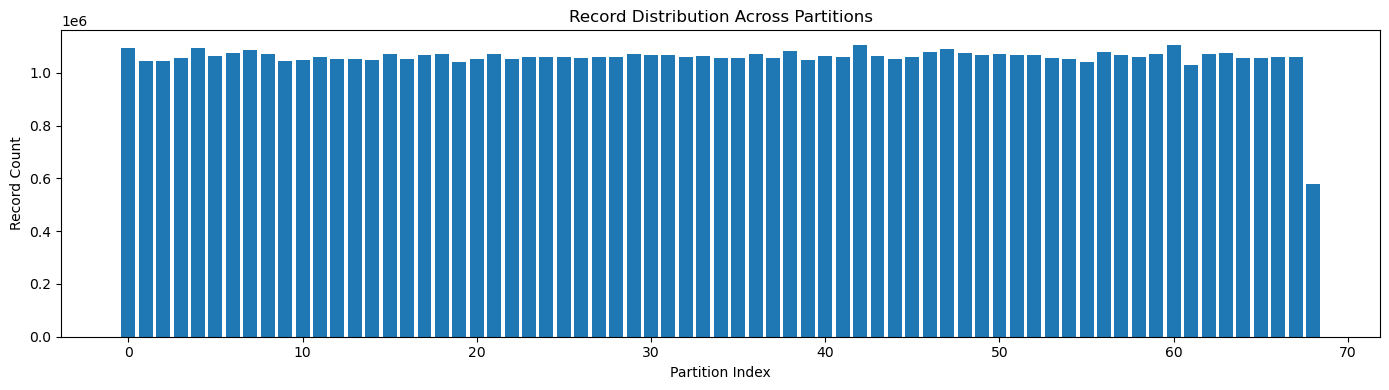

In [19]:
import matplotlib.pyplot as plt

# Uses the counts already collected in 1.3.2, so no new Spark job is triggered
plt.figure(figsize=(14, 4))
plt.bar([i for i, _ in partition_counts], [c for _, c in partition_counts])
plt.xlabel("Partition Index")
plt.ylabel("Record Count")
plt.title("Record Distribution Across Partitions")
plt.tight_layout()
plt.show()

The workload is **evenly distributed**. In the Summary Metrics for the 69 tasks, input size is 128.1 MiB from the 25th percentile to the maximum, and records per task range only from about 1.05 to 1.11 million (roughly 5% variation), since Spark splits the file by bytes and row lengths differ slightly.

The only outlier is the minimum task (69.1 MiB, 580,174 records), which is the final partition holding the remainder of the file after 128 MiB splits. This is not data skew. Task durations (3.8–4.9 min for full-size partitions) are also consistent; they are longer than usual because another run of the same job overlapped and shared the four cores.

1.3.5) Provide a concise explanation detailing how Spark determines the initial number and approximate size of input partitions when reading from a CSV file.

Spark determines input partitions automatically from the file size and its configuration; these settings were left at their defaults.

1. **Split size.** Spark computes a maximum split size:
   `min(maxPartitionBytes, max(openCostInBytes, totalBytes / defaultParallelism))`
   - `spark.sql.files.maxPartitionBytes` = 128 MiB (upper limit per partition)
   - `spark.sql.files.openCostInBytes` = 4 MiB (estimated cost of opening a file, which prevents many tiny partitions)
   - `defaultParallelism` = 4 (from `local[4]`)

   Here, 8.6 GiB / 4 ≈ 2.15 GiB, so the split size is capped at **128 MiB**.

2. **Number of partitions.** The file is cut into byte ranges of that size: 8.6 GiB / 128 MiB ≈ 68.8, giving **69 partitions**. This matches `getNumPartitions()` and the 69 tasks in the Spark UI, where 68 tasks read 128.1 MiB and the last reads the remaining 69.1 MiB.

3. **Splitting is by bytes, not rows.** Record counts per partition vary slightly because row lengths differ, and each task finishes reading any row that crosses its boundary.

4. **Splittability.** This only works because uncompressed CSV is splittable. A gzip-compressed CSV must be read from the start, so it would form a single partition regardless of size.

## Part 2. Working with DataFrames (35%) <a class="anchor" name="2-dataframes"></a>
In this section, you need to use DataFrame functions to answer the queries.

2.1 Create the time attributes  
2.1.1) From ArrivalTime, create columns for: year; month; day of week;  arrival hour and arrival minute;.

In [20]:
from pyspark.sql.functions import (
    col, year, month, dayofweek, hour, minute, when
)

# dayofweek follows Spark's convention (1 = Sunday), as required by 2.1.2
parking_time = (
    parking_clean
    .withColumn("Year", year(col("ArrivalTime")))
    .withColumn("Month", month(col("ArrivalTime")))
    .withColumn("DayOfWeek", dayofweek(col("ArrivalTime")))
    .withColumn("ArrivalHour", hour(col("ArrivalTime")))
    .withColumn("ArrivalMinute", minute(col("ArrivalTime")))
)

parking_time.select("ArrivalTime", "Year", "Month", "DayOfWeek",
                    "ArrivalHour", "ArrivalMinute").show(5, truncate=False)

+-------------------+----+-----+---------+-----------+-------------+
|ArrivalTime        |Year|Month|DayOfWeek|ArrivalHour|ArrivalMinute|
+-------------------+----+-----+---------+-----------+-------------+
|2018-10-23 06:49:29|2018|10   |3        |6          |49           |
|2018-02-07 19:30:00|2018|2    |4        |19         |30           |
|2018-11-22 07:22:38|2018|11   |5        |7          |22           |
|2018-09-18 21:24:56|2018|9    |3        |21         |24           |
|2018-01-04 00:00:00|2018|1    |5        |0          |0            |
+-------------------+----+-----+---------+-----------+-------------+
only showing top 5 rows


2.1.2) With day of week and hour and minutes, create a new column named isPeak and set the value to True or False (i.e. True = Peak Hour, False = Non-peak hour).  
- Peak hours are:
- Weekdays 7:00 - 9:00 am (excluding 9:00 am) and 4:00 - 6:30 pm ( excluding 6:30 pm).
- Non-peak hours are times outside these periods.
- Represent day of week using Spark’s convention: 1 = Sunday, 2 = Monday……

In [21]:
from pyspark.sql.functions import lit

# Spark's dayofweek: 1 = Sunday, so Monday-Friday is 2-6
is_weekday = col("DayOfWeek").between(2, 6)

# 07:00-08:59; 09:00 is excluded
morning_peak = col("ArrivalHour").isin(7, 8)

# 16:00-18:29; minutes are needed because 18:30 is excluded
evening_peak = (
    col("ArrivalHour").isin(16, 17)
    | ((col("ArrivalHour") == 18) & (col("ArrivalMinute") < 30))
)

parking_time = parking_time.withColumn(
    "isPeak",
    when(col("ArrivalTime").isNull(), lit(None).cast("boolean"))
    .otherwise(is_weekday & (morning_peak | evening_peak))
)

print("isPeak distribution:")
parking_time.groupBy("isPeak").count().show()

isPeak distribution:
+------+--------+
|isPeak|   count|
+------+--------+
|  true|15701975|
| false|57210607|
+------+--------+



2.1.3) Display five rows containing ArrivalTime, year, month, day of week, arrival hour, arrival minute and isPeak, and print the relevant schema.

In [22]:
time_cols = parking_time.select(
    "ArrivalTime", "Year", "Month", "DayOfWeek",
    "ArrivalHour", "ArrivalMinute", "isPeak"
)

time_cols.printSchema()
time_cols.show(5, truncate=False)

root
 |-- ArrivalTime: timestamp (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- DayOfWeek: integer (nullable = true)
 |-- ArrivalHour: integer (nullable = true)
 |-- ArrivalMinute: integer (nullable = true)
 |-- isPeak: boolean (nullable = true)

+-------------------+----+-----+---------+-----------+-------------+------+
|ArrivalTime        |Year|Month|DayOfWeek|ArrivalHour|ArrivalMinute|isPeak|
+-------------------+----+-----+---------+-----------+-------------+------+
|2018-10-23 06:49:29|2018|10   |3        |6          |49           |false |
|2018-02-07 19:30:00|2018|2    |4        |19         |30           |false |
|2018-11-22 07:22:38|2018|11   |5        |7          |22           |true  |
|2018-09-18 21:24:56|2018|9    |3        |21         |24           |false |
|2018-01-04 00:00:00|2018|1    |5        |0          |0            |false |
+-------------------+----+-----+---------+-----------+-------------+------+
only showing top 5

2.2 Join the cleaned parking sensor data with both lookup tables to add the area and street names. (Note:The area and street lookup table is provided in JSON format).  
Select an appropriate join type;
- Report the number of parking records that do not match an area look up row and the number that do not match a street lookup row. 
- Identify a suitable join strategy for these joins and justify your choice.
- Display the first five joined records with the following columns: DeviceId, AreaId, AreaName, StreetId, and StreetName.

In [23]:
from pyspark.sql.functions import broadcast, lit, sum as _sum

# A constant flag marks rows that matched a lookup row Needed because AreaName can be null even when matched (AreaId 7, see 1.2.1)
area_lookup = area_clean.withColumn("_area_matched", lit(True))
street_lookup = street_clean.withColumn("_street_matched", lit(True))

# Left join: unmatched records are kept so they can be counted below.Broadcast: lookups are tiny (38 and 126 rows)
parking_joined = (
    parking_time
    .join(broadcast(area_lookup),   on="AreaId",   how="left")
    .join(broadcast(street_lookup), on="StreetId", how="left")
)

print("Join completed. Columns:")
print(parking_joined.columns)

Join completed. Columns:
['StreetId', 'AreaId', 'DeviceIdRaw', 'ArrivalTimeRaw', 'DepartureTimeRaw', 'StreetMarker', 'SignPlateId', 'Sign', 'BetweenStreet1Id', 'BetweenStreet2Id', 'SideOfStreet', 'SideName', 'BayId', 'InViolation', 'VehiclePresent', 'ArrivalTime', 'DepartureTime', 'DeviceId', 'DurationMinutes', 'HasValidArrival', 'HasValidDuration', 'Year', 'Month', 'DayOfWeek', 'ArrivalHour', 'ArrivalMinute', 'isPeak', 'AreaName', '_area_matched', 'StreetName', '_street_matched']


In [24]:
# 2.2 (a) Count parking records with no matching lookup row _matched is null only when no lookup row was found
from pyspark.sql.functions import count as _count

# _matched is null only when no lookup row was found AreaName alone is not reliable
match_summary = parking_joined.agg(
    _count("*").alias("TotalRecords"),

    _sum(when(col("AreaId").isNull(), 1).otherwise(0))
        .alias("NullAreaId"),
    _sum(when(col("AreaId").isNotNull() & col("_area_matched").isNull(), 1).otherwise(0))
        .alias("UnmatchedAreaId"),
    _sum(when(col("_area_matched").isNull(), 1).otherwise(0))
        .alias("TotalNoAreaMatch"),

    _sum(when(col("StreetId").isNull(), 1).otherwise(0))
        .alias("NullStreetId"),
    _sum(when(col("StreetId").isNotNull() & col("_street_matched").isNull(), 1).otherwise(0))
        .alias("UnmatchedStreetId"),
    _sum(when(col("_street_matched").isNull(), 1).otherwise(0))
        .alias("TotalNoStreetMatch"),
)

match_summary.show(truncate=False, vertical=True)

-RECORD 0----------------------
 TotalRecords       | 72912582 
 NullAreaId         | 0        
 UnmatchedAreaId    | 0        
 TotalNoAreaMatch   | 0        
 NullStreetId       | 0        
 UnmatchedStreetId  | 0        
 TotalNoStreetMatch | 0        



In [25]:
# 2.2 (b) Confirm the physical plan uses BroadcastHashJoin
parking_joined.select("DeviceId", "AreaId", "AreaName",
                      "StreetId", "StreetName").explain(mode="formatted")

# 2.2 (c) First five joined records
parking_joined.select(
    "DeviceId", "AreaId", "AreaName", "StreetId", "StreetName"
).show(5, truncate=False)

== Physical Plan ==
AdaptiveSparkPlan (19)
+- Project (18)
   +- BroadcastHashJoin LeftOuter BuildRight (17)
      :- Project (10)
      :  +- BroadcastHashJoin LeftOuter BuildRight (9)
      :     :- Project (2)
      :     :  +- Scan csv  (1)
      :     +- BroadcastExchange (8)
      :        +- Project (7)
      :           +- Filter (6)
      :              +- Generate (5)
      :                 +- Filter (4)
      :                    +- Scan json  (3)
      +- BroadcastExchange (16)
         +- Project (15)
            +- Filter (14)
               +- Generate (13)
                  +- Filter (12)
                     +- Scan json  (11)


(1) Scan csv 
Output [3]: [DeviceId#0, StreetId#6, AreaId#14]
Batched: false
Location: InMemoryFileIndex [file:/home/student/A1/fit5202_2026_s2_dataset_v2/sensordata.csv]
ReadSchema: struct<DeviceId:string,StreetId:int,AreaId:int>

(2) Project
Output [3]: [StreetId#6, AreaId#14, try_cast(DeviceId#0 as int) AS DeviceId#590]
Input [3]: [DeviceId

**Join type: left outer join.** Unmatched parking records are kept so that the unmatched counts above can be reported, and so records with a valid arrival time remain available for queries that do not need area or street names. An inner join would silently drop them.

**Join strategy: broadcast hash join.** The lookup tables are tiny (38 areas, 126 streets) while the parking data is 8.6 GB across 69 partitions. A sort-merge join would shuffle both sides on the join key, redistributing the full 8.6 GB over the network. Broadcasting copies each lookup table to every executor instead, so the large table is never moved and each task performs a local hash lookup.

`broadcast()` is called explicitly rather than relying on `spark.sql.autoBroadcastJoinThreshold`, so the strategy is guaranteed. The physical plan above confirms both joins run as `BroadcastHashJoin LeftOuter BuildRight`.

**Result:** 0 parking records failed to match an area lookup row and 0 failed to match a street lookup row, so the foreign keys are fully consistent with both lookup tables.

### 2.3 Compare Parking Activity and Violation Rates
The council would like to compare parking activity and violation patterns during peak and off-peak periods.  
For each parking area:
- PeakDailyAverage: the average number of valid peak-hour sessions per active weekday.
- PeakViolationRate: percentage of valid peak-hour sessions marked as InViolation.
- OffPeakDailyAverage: the average number of valid off-peak sessions per active day.
- OffPeakViolationRate: the percentage of valid off-peak sessions marked as InViolation.
- TotalValidSessions: total peak and off-peak sessions.
1) Display the ten areas with the highest TotalValidSessions, ordered by TotalValidSessions descending. If counts are equal, order by AreaId ascending. 
1) Briefly compare the peak and off-peak results and discuss whether higher parking activity appears to correspond with higher violation rates among these areas.
Note:  
- Violation rate = (sessions where Inviolation is true) / (sessions with a valid Inviolation value in the same period) * 100%.
- A valid session must have a non-null AreaID, and a successfully parsed ArrivalTime. 
- Calculate each violation rate using sessions with a valid InViolation value in the corresponding period.
- A missing DepartureTime does not invalidate a session because duration is not used in this task.
- An active day is a date on which the area has at least one valid parking session.


In [26]:
from pyspark.sql.functions import (
    col, to_date, when, sum as _sum, countDistinct, round as _round
)

# 2.3 (1)-(5) Peak and off-peak metrics per area
# Valid session = non-null AreaId and parsed ArrivalTime
# HasValidDuration is not applied: duration is not used in this task
parking_valid = (
    parking_joined
    .filter(col("AreaId").isNotNull() & col("HasValidArrival"))
    .withColumn("ArrivalDate", to_date(col("ArrivalTime")))
)

# All base counts in one groupBy to avoid repeated shuffles
area_stats = (
    parking_valid
    .groupBy("AreaId", "AreaName")
    .agg(
        _sum(when(col("isPeak"), 1).otherwise(0)).alias("PeakSessions"),
        _sum(when(~col("isPeak"), 1).otherwise(0)).alias("OffPeakSessions"),

        # when() returns null when false, and countDistinct ignores nulls
        countDistinct(when(col("isPeak"), col("ArrivalDate")))
            .alias("ActivePeakWeekdays"),
        countDistinct(when(~col("isPeak"), col("ArrivalDate")))
            .alias("ActiveOffPeakDays"),

        _sum(when(col("isPeak") & col("InViolation"), 1)
             .otherwise(0)).alias("PeakViolations"),
        _sum(when(~col("isPeak") & col("InViolation"), 1)
             .otherwise(0)).alias("OffPeakViolations"),

        # Denominator is sessions with a non-null InViolation value
        _sum(when(col("isPeak") & col("InViolation").isNotNull(), 1)
             .otherwise(0)).alias("PeakViolationBase"),
        _sum(when(~col("isPeak") & col("InViolation").isNotNull(), 1)
             .otherwise(0)).alias("OffPeakViolationBase"),
    )
)

# when(denominator > 0) guards against areas with no sessions in a period
area_stats = (
    area_stats
    .withColumn("PeakDailyAverage",
        when(col("ActivePeakWeekdays") > 0,
             _round(col("PeakSessions") / col("ActivePeakWeekdays"), 2)))
    .withColumn("PeakViolationRate",
        when(col("PeakViolationBase") > 0,
             _round(col("PeakViolations") * 100.0 / col("PeakViolationBase"), 2)))
    .withColumn("OffPeakDailyAverage",
        when(col("ActiveOffPeakDays") > 0,
             _round(col("OffPeakSessions") / col("ActiveOffPeakDays"), 2)))
    .withColumn("OffPeakViolationRate",
        when(col("OffPeakViolationBase") > 0,
             _round(col("OffPeakViolations") * 100.0 / col("OffPeakViolationBase"), 2)))
    .withColumn("TotalValidSessions",
        col("PeakSessions") + col("OffPeakSessions"))
)

# Only ~38 rows; cached for the ranking and discussion below
area_stats.cache()
print(f"Areas computed: {area_stats.count()}")

Areas computed: 38


In [27]:
# 2.3.6 Top Ten Areas by TotalValidSessions
# Second sort key breaks ties deterministically, as required
top10_areas = (
    area_stats
    .select(
        "AreaId", "AreaName",
        "PeakDailyAverage", "PeakViolationRate",
        "OffPeakDailyAverage", "OffPeakViolationRate",
        "TotalValidSessions"
    )
    .orderBy(col("TotalValidSessions").desc(), col("AreaId").asc())
    .limit(10)
)

top10_areas.show(10, truncate=False)

+------+---------------+----------------+-----------------+-------------------+--------------------+------------------+
|AreaId|AreaName       |PeakDailyAverage|PeakViolationRate|OffPeakDailyAverage|OffPeakViolationRate|TotalValidSessions|
+------+---------------+----------------+-----------------+-------------------+--------------------+------------------+
|35    |Docklands      |4013.64         |6.48             |10054.13           |5.25                |9434638           |
|16    |Queensberry    |2337.38         |5.08             |6546.26            |2.68                |5998885           |
|38    |Southbank      |2101.92         |4.68             |5309.37            |3.56                |4973044           |
|24    |Jolimont       |2117.11         |2.74             |3995.09            |4.19                |4021552           |
|3     |Banks          |1485.88         |0.78             |3900.84            |0.8                 |3623243           |
|13    |Princes Theatre|1192.61         

In [28]:
# 2.3.7 Supporting statistics for the discussion below (not required)
from pyspark.sql.functions import avg, corr

# Averages across all 38 areas, not just the top ten
print("Overall comparison across all areas:")
area_stats.select(
    _round(avg("PeakDailyAverage"), 2).alias("AvgPeakDailyAvg"),
    _round(avg("OffPeakDailyAverage"), 2).alias("AvgOffPeakDailyAvg"),
    _round(avg("PeakViolationRate"), 2).alias("AvgPeakViolationRate"),
    _round(avg("OffPeakViolationRate"), 2).alias("AvgOffPeakViolationRate"),
).show(truncate=False)

# Correlation ranges from -1 to 1; it shows association, not causation
print("Correlation between activity level and violation rate:")
area_stats.select(
    _round(corr("TotalValidSessions", "PeakViolationRate"), 3)
        .alias("Corr_Total_vs_PeakVR"),
    _round(corr("TotalValidSessions", "OffPeakViolationRate"), 3)
        .alias("Corr_Total_vs_OffPeakVR"),
    _round(corr("PeakDailyAverage", "PeakViolationRate"), 3)
        .alias("Corr_PeakDaily_vs_PeakVR"),
).show(truncate=False)

Overall comparison across all areas:
+---------------+------------------+--------------------+-----------------------+
|AvgPeakDailyAvg|AvgOffPeakDailyAvg|AvgPeakViolationRate|AvgOffPeakViolationRate|
+---------------+------------------+--------------------+-----------------------+
|815.3          |2116.06           |5.37                |3.81                   |
+---------------+------------------+--------------------+-----------------------+

Correlation between activity level and violation rate:
+--------------------+-----------------------+------------------------+
|Corr_Total_vs_PeakVR|Corr_Total_vs_OffPeakVR|Corr_PeakDaily_vs_PeakVR|
+--------------------+-----------------------+------------------------+
|-0.185              |-0.111                 |-0.104                  |
+--------------------+-----------------------+------------------------+



**Peak vs off-peak activity.** Off-peak daily averages are about 2.5–3 times the peak averages (Docklands: 10,054 vs 4,014; across all areas: 2,116 vs 815). This reflects the time each period covers rather than lower peak demand: peak hours span only 4.5 hours per weekday, while off-peak covers the remaining 19.5 hours plus weekends. On a per-hour basis Docklands sees roughly 892 peak sessions per hour against 515 off-peak, so peak periods are substantially busier.

**Peak vs off-peak violation rates.** Violation rates are consistently higher during peak hours. Across all 38 areas the average peak rate is 5.37% against 3.81% off-peak, and six of the top ten areas follow this pattern, most clearly Queensberry (5.08% vs 2.68%) and Titles (5.05% vs 3.47%). Three areas (Jolimont, Supreme, County) show the opposite, and Banks is effectively unchanged.

**Does higher activity correspond with higher violation rates?** Within the top ten the busiest area, Docklands (9.4 million sessions), also has the highest peak violation rate (6.48%), which suggests a positive link. Across all 38 areas, however, the correlation between activity and violation rate is close to zero and slightly negative (-0.185 for total sessions against peak violation rate, -0.104 for peak daily average). Banks illustrates this: it ranks fifth by activity yet has the lowest violation rate of the ten (0.78%).

Activity volume therefore does not appear to explain violation behaviour. The apparent link at the top of the ranking does not hold once all areas are considered, which suggests local factors such as time limits, pricing and enforcement intensity play a larger role.

### 2.4 Identify high-use and long-stay parking bays  
Parking planners would like to identify bays with frequent vehicle turnover and bays that are commonly occupied for longer periods.  
For each BayId, calculate:  
1. the total number of valid parking sessions;
1. the total number of sessions with a valid duration;
1. the average parking duration in minutes, rounded to two decimal places
1. the percentage of sessions marked as InViolation, rounded to two decimal places  
Identify and display:  
1. the top 5 bays with the highest turnover, order the turnover result by totalSessions descending, use BayID ascending to resolve ties.
1. the top 5 bays with the longest average stay, order the longest-stay result by AverageDurationMinutes descending, use BayID ascending to resolve ties.
1. For both top-5 results, display BayID, TotalSessions, ValidDurationSessions, AverageDurationMinutes and ViolationRates.
Note:  
- A valid session must have a non-null identifier required by the query, a successfully parsed ArrivalTime.
- Define turnover as the total number of valid sessions recorded for a bay during the observation period


In [29]:
# 2.4 Bay-Level Metrics (1)-(4)
from pyspark.sql.functions import col, when, count, sum as _sum, round as _round

# Valid session: non-null BayId (the identifier for this query) and a parsed ArrivalTime
bay_valid = parking_joined.filter(
    col("BayId").isNotNull() & col("HasValidArrival")
)

bay_stats = (
    bay_valid
    .groupBy("BayId")
    .agg(
        # Turnover, as defined in the note
        count("*").alias("TotalSessions"),

        _sum(when(col("HasValidDuration"), 1).otherwise(0))
            .alias("ValidDurationSessions"),

        # Summed manually because avg() ignores nulls but not the
        # negative durations identified in 1.2.5
        _sum(when(col("HasValidDuration"), col("DurationMinutes")).otherwise(0.0))
            .alias("_TotalDuration"),

        _sum(when(col("InViolation"), 1).otherwise(0))
            .alias("_Violations"),
        _sum(when(col("InViolation").isNotNull(), 1).otherwise(0))
            .alias("_ViolationBase"),
    )
)

bay_stats = (
    bay_stats
    # Denominator is ValidDurationSessions, not TotalSessions
    .withColumn("AverageDurationMinutes",
        when(col("ValidDurationSessions") > 0,
             _round(col("_TotalDuration") / col("ValidDurationSessions"), 2)))
    .withColumn("ViolationRates",
        when(col("_ViolationBase") > 0,
             _round(col("_Violations") * 100.0 / col("_ViolationBase"), 2)))
    .drop("_TotalDuration", "_Violations", "_ViolationBase")
)

bay_stats.cache()
print(f"Bays computed: {bay_stats.count():,}")

Bays computed: 5,300


In [30]:
# 2.4 (a) Top 5 Bays by Turnover
# Turnover is TotalSessions, as defined in the note
top5_turnover = (
    bay_stats
    .select("BayId", "TotalSessions", "ValidDurationSessions",
            "AverageDurationMinutes", "ViolationRates")
    .orderBy(col("TotalSessions").desc(), col("BayId").asc())
    .limit(5)
)

print("Top 5 bays by turnover (TotalSessions):")
top5_turnover.show(5, truncate=False)

Top 5 bays by turnover (TotalSessions):
+-----+-------------+---------------------+----------------------+--------------+
|BayId|TotalSessions|ValidDurationSessions|AverageDurationMinutes|ViolationRates|
+-----+-------------+---------------------+----------------------+--------------+
|1063 |354011       |354011               |2.26                  |0.01          |
|1599 |269787       |269787               |2.01                  |0.04          |
|6048 |233744       |233744               |2.79                  |0.0           |
|1060 |193523       |193523               |4.19                  |0.06          |
|1597 |155190       |155190               |4.52                  |0.08          |
+-----+-------------+---------------------+----------------------+--------------+



In [31]:
# 2.4 (b) Top 5 Bays by Average Stay
# Bays with no valid-duration sessions have a null average; excluded so nulls cannot affect the descending order
top5_longstay = (
    bay_stats
    .filter(col("AverageDurationMinutes").isNotNull())
    .select("BayId", "TotalSessions", "ValidDurationSessions",
            "AverageDurationMinutes", "ViolationRates")
    .orderBy(col("AverageDurationMinutes").desc(), col("BayId").asc())
    .limit(5)
)

print("Top 5 bays by average stay duration:")
top5_longstay.show(5, truncate=False)

Top 5 bays by average stay duration:
+-----+-------------+---------------------+----------------------+--------------+
|BayId|TotalSessions|ValidDurationSessions|AverageDurationMinutes|ViolationRates|
+-----+-------------+---------------------+----------------------+--------------+
|2469 |33           |33                   |14885.57              |21.21         |
|4809 |12649        |12649                |9677.11               |2.26          |
|2467 |4            |4                    |8094.98               |0.0           |
|2468 |22           |22                   |1799.09               |18.18         |
|2478 |36           |36                   |1207.54               |27.78         |
+-----+-------------+---------------------+----------------------+--------------+



**Observations and data quality**

**High-turnover bays (2.4 a).** The top five bays average only 2.01–4.52 minutes per session with near-zero violation rates (0.00%–0.08%). Such short stays combined with almost no violations suggest these are not ordinary parking bays but loading zones, drop-off points or taxi ranks, where drivers typically stay with the vehicle. For these bays ValidDurationSessions equals TotalSessions, so the duration data is complete.

**Longest-stay bays (2.4 b) — clear data quality issues.** Three of the top five average more than five days per session (BayId 2469: 14,885.57 minutes, about 10.3 days; 4809: 9,677.11 minutes, about 6.7 days; 2467: 8,094.98 minutes, about 5.6 days), which is not plausible parking behaviour.

Three points indicate these values should not be read at face value:

1. **Very small samples.** BayId 2467 has only 4 sessions, 2468 has 22 and 2469 has 33. A single extreme record dominates an average computed from so few observations.
2. **Clustered bay identifiers.** 2467, 2468, 2469 and 2478 are consecutive, so they are likely on the same street segment. This points to a systematic fault in one group of sensors rather than genuine long-stay behaviour at each bay independently.
3. **Most likely cause: missed departure events.** If a departure is not recorded, the session stays open until the next arrival triggers a new event, so the idle period between vehicles is absorbed into one session.

BayId 4809 is the only bay with a large sample (12,649 sessions), but its 6.7-day average is equally implausible: 12,649 sessions at that length would total about 84,700 days, more than 100 times the roughly 730-day observation period. The sessions must therefore overlap heavily, which is consistent with the missed-departure explanation above.

**Impact on the analysis.** As specified, this section ranks bays by AverageDurationMinutes with no minimum session threshold, so the result is dominated by small-sample bays. For planning purposes a minimum session count (for example 100) or a median rather than a mean would reduce the influence of these outliers.

### 2.5 Combine parking activity with traffic volume
The council would like to identify when an area experiences unusually high traffic and parking activity at the same time.  
The traffic count dataset is measured by sensors during 10-minute time blocks. A time block begins at 00, 10, 20, 30, 40, or 50 minutes past the hour. For example, times from 00:00:00 inclusive to 00:10:00 exclusive belong to the block beginning at 00:00:00. A traffic record with: 2018, 1, 1, 0, 0 is the first 10-minute block on 1/1/2018, and belongs to the block 2018-01-01 00:00:00 to 2018-01-01 00:09:59.  
For each area-time block:  
- Define ParkingSessions as the number of parking sessions beginning within the block.
- Define TrafficVolume as the sum of traffic_count within the block.

1. Now, you need to think of a strategy to combine parking activity and traffic volume. Select an appropriate join type and justify your choice. 

In [32]:
from pyspark.sql.functions import (
    col, make_timestamp, lit, floor, expr, count, sum as _sum,
    avg, when, round as _round
)

# d_minute is the block index 0-5, so start minute = d_minute * 10
traffic_blocks = (
    traffic_clean
    .withColumn(
        "BlockStart",
        make_timestamp(
            col("d_year"), col("d_month"), col("d_day"),
            col("d_hour"), col("d_minute") * 10, lit(0)
        )
    )
    .groupBy("AreaId", "BlockStart")
    .agg(_sum("traffic_count").alias("TrafficVolume"))
)

# 06:49:29 -> 06:40:00
parking_blocks = (
    parking_valid
    .withColumn(
        "BlockStart",
        expr("date_trunc('hour', ArrivalTime) + make_interval(0,0,0,0,0,floor(minute(ArrivalTime)/10)*10,0)")
    )
    .groupBy("AreaId", "BlockStart")
    .agg(count("*").alias("ParkingSessions"))
)

print("Traffic blocks sample:")
traffic_blocks.show(5, truncate=False)
print("Parking blocks sample:")
parking_blocks.show(5, truncate=False)

Traffic blocks sample:
+------+-------------------+-------------+
|AreaId|BlockStart         |TrafficVolume|
+------+-------------------+-------------+
|34    |2018-01-01 02:00:00|18           |
|14    |2018-01-01 02:30:00|23           |
|4     |2018-01-01 04:20:00|14           |
|26    |2018-01-01 05:20:00|15           |
|19    |2018-01-01 07:10:00|75           |
+------+-------------------+-------------+
only showing top 5 rows
Parking blocks sample:
+------+-------------------+---------------+
|AreaId|BlockStart         |ParkingSessions|
+------+-------------------+---------------+
|35    |2018-02-21 19:20:00|89             |
|35    |2018-02-08 19:20:00|77             |
|35    |2018-04-27 20:00:00|44             |
|35    |2018-01-03 19:10:00|70             |
|35    |2018-09-23 07:30:00|455            |
+------+-------------------+---------------+
only showing top 5 rows


**Strategy.** The two datasets are at different grains: parking is event-level, while traffic is already aggregated into 10-minute blocks. Both sides are therefore reduced to the same `(AreaId, BlockStart)` grain before joining — arrival times are floored to the block start, and traffic counts are summed because each area-block contains readings from several sensors.

**Join type: inner join.** The task analyses "the matched area-time blocks", so only blocks present in both datasets are relevant. A block with parking activity but no traffic reading (or the reverse) cannot be used to compare the two measures or to test whether both are above average.

This is the opposite of 2.2, where a left join was required in order to count the records that did not match a lookup row. Here the unmatched blocks are not part of the question, so keeping them would add rows with null measures that would distort both averages and the above-average counts.

2. Across the matched area-time blocks, define high parking activity and high traffic volume as values greater than their respective averages.  
Display a summary containing:  
the average ParkingSessions, average TrafficVolume, number of matched area-time blocks, and the number where both measures are above average.   


In [33]:
sc.setJobDescription(f"A1-P2-TrafficJoin-{student_auth_code}")

# Inner join: only blocks present on both sides can be compared
matched_blocks = (
    parking_blocks
    .join(traffic_blocks, on=["AreaId", "BlockStart"], how="inner")
)

matched_blocks.cache()

# Averages are taken over all matched blocks, not per area
averages = matched_blocks.select(
    avg("ParkingSessions").alias("AvgParkingSessions"),
    avg("TrafficVolume").alias("AvgTrafficVolume"),
).collect()[0]

avg_parking = averages["AvgParkingSessions"]
avg_traffic = averages["AvgTrafficVolume"]

summary = matched_blocks.agg(
    _round(lit(avg_parking), 2).alias("AverageParkingSessions"),
    _round(lit(avg_traffic), 2).alias("AverageTrafficVolume"),
    count("*").alias("MatchedAreaTimeBlocks"),
    _sum(when((col("ParkingSessions") > avg_parking)
              & (col("TrafficVolume") > avg_traffic), 1).otherwise(0))
        .alias("BothAboveAverage"),
)

print("Summary of matched area-time blocks:")
summary.show(truncate=False, vertical=True)

sc.setJobDescription(None)

Summary of matched area-time blocks:
-RECORD 0-------------------------
 AverageParkingSessions | 21.17   
 AverageTrafficVolume   | 184.67  
 MatchedAreaTimeBlocks  | 3444626 
 BothAboveAverage       | 821208  



3. Display the ten above-average combinations with the highest ParkingSessions, display AreaID, AreaName, BlockStart, ParkingSessions, TrafficVolume, order the result by ParkingSessions and TrafficVolume in descending order. If values are equal, order by AreaId and BlockStart in ascending order.

In [34]:
# 2.5.3 Top Ten Above-Average Blocks
from pyspark.sql.functions import broadcast

# AreaName was dropped by the groupBy, so the lookup is joined again
top10_blocks = (
    matched_blocks
    .filter((col("ParkingSessions") > avg_parking)
            & (col("TrafficVolume") > avg_traffic))
    .join(broadcast(area_clean), on="AreaId", how="left")
    .select("AreaId", "AreaName", "BlockStart", "ParkingSessions", "TrafficVolume")
    .orderBy(
        col("ParkingSessions").desc(),
        col("TrafficVolume").desc(),
        col("AreaId").asc(),
        col("BlockStart").asc()
    )
    .limit(10)
)

top10_blocks.show(10, truncate=False)

+------+-----------+-------------------+---------------+-------------+
|AreaId|AreaName   |BlockStart         |ParkingSessions|TrafficVolume|
+------+-----------+-------------------+---------------+-------------+
|16    |Queensberry|2019-05-03 00:00:00|951            |11642        |
|16    |Queensberry|2019-05-04 00:00:00|866            |8958         |
|35    |Docklands  |2018-02-10 00:00:00|763            |5604         |
|16    |Queensberry|2019-11-20 07:30:00|739            |8275         |
|16    |Queensberry|2019-12-05 07:30:00|733            |7154         |
|16    |Queensberry|2019-12-10 07:30:00|723            |4431         |
|16    |Queensberry|2019-12-06 07:30:00|722            |7176         |
|16    |Queensberry|2019-12-24 07:30:00|721            |8095         |
|16    |Queensberry|2019-12-20 07:30:00|716            |10296        |
|16    |Queensberry|2019-11-29 07:30:00|716            |8389         |
+------+-----------+-------------------+---------------+-------------+



4. Before running the query, you must set:  
sc.setJobDescription(f"A1-P2-TrafficJoin-{student_auth_code}")  
Students must include:  
- the formatted physical plan using explain(mode="formatted");
- Spark UI screenshots showing the job description, any Exchange, and the relevant shuffle-read, shuffle-write values.
- a short explanation of why data movement was or was not required.


In [35]:
top10_blocks.explain(mode="formatted")

== Physical Plan ==
AdaptiveSparkPlan (83)
+- TakeOrderedAndProject (82)
   +- Project (81)
      +- BroadcastHashJoin LeftOuter BuildRight (80)
         :- Filter (73)
         :  +- InMemoryTableScan (1)
         :        +- InMemoryRelation (2)
         :              +- AdaptiveSparkPlan (72)
                           +- == Final Plan ==
                              ResultQueryStage (41)
                              +- * Project (40)
                                 +- * SortMergeJoin Inner (39)
                                    :- * Sort (30)
                                    :  +- * HashAggregate (29)
                                    :     +- ShuffleQueryStage (28), Statistics(sizeInBytes=546.6 MiB, rowCount=1.79E+7)
                                    :        +- Exchange (27)
                                    :           +- * HashAggregate (26)
                                    :              +- * Project (25)
                                    :                 

**(a) Jobs tab with job description `A1-P2-TrafficJoin-ylii0798`**

![Jobs](screenshot/p2_jobs.jpg)

**(b) Stage reading 8.6 GiB and writing 183.4 MiB of shuffle output**

![Shuffle write](screenshot/p2_shuffle_write.jpg)

**(c) Downstream stage reading 231.5 MiB across 200 tasks**

![Shuffle read](screenshot/p2_shuffle_read.jpg)

**Why data movement was required**

Both sides are aggregated by `(AreaId, BlockStart)` and joined on the same keys, so rows sharing a key must be co-located. The physical plan shows two `Exchange hashpartitioning(AreaId, BlockStart, 200)` operators feeding a `SortMergeJoin Inner`; the shuffled inputs are 546.6 MiB and 105.2 MiB, far above the broadcast threshold, so neither side could be broadcast. By contrast the 38-row area lookup in the same plan uses a `BroadcastHashJoin`.

In the Spark UI, the stage reading 8.6 GiB writes 183.4 MiB of shuffle output across 69 tasks, and the downstream stage reads 231.5 MiB across 200 tasks. The shuffled volume is far below the input size because `partial_count` and `partial_sum` aggregate within each partition before the exchange.

### 2.6 Exploratory analysis  <a class="anchor" name="2.6"></a>
Produce two suitable plots exploring relationships among parking activity, duration, violation rate, or traffic volume.  
For each plot:
1. State the question being investigated;
1. Display the first five rows and the row count of the aggregated dataset used to create the plot
1. Select the appropriate plot type and briefly justify your choice.
1. Explain the observed pattern shown by the plot.
1. identify one limitation of the interpretation.


### 2.6 Plot 1: Peak vs Off-Peak Violation Rate by Area

**Question:** Is the peak violation rate higher than the off-peak rate across areas?

**Plot type:** Scatter plot with a `y = x` reference line: both variables are continuous, and the line makes it directly readable which areas have a higher peak rate. Point size shows total sessions.

Row count: 38
+------+-----------+-----------------+--------------------+------------------+
|AreaId|AreaName   |PeakViolationRate|OffPeakViolationRate|TotalValidSessions|
+------+-----------+-----------------+--------------------+------------------+
|35    |Docklands  |6.48             |5.25                |9434638           |
|16    |Queensberry|5.08             |2.68                |5998885           |
|38    |Southbank  |4.68             |3.56                |4973044           |
|24    |Jolimont   |2.74             |4.19                |4021552           |
|3     |Banks      |0.78             |0.8                 |3623243           |
+------+-----------+-----------------+--------------------+------------------+
only showing top 5 rows


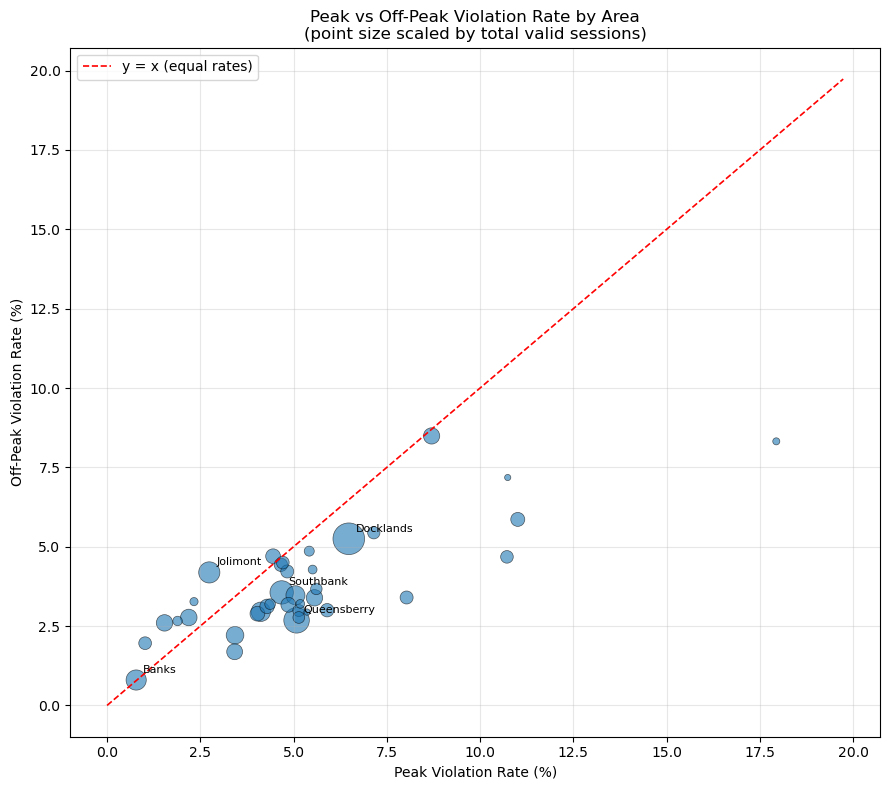

Areas where peak violation rate exceeds off-peak: 30 / 38


In [36]:
import matplotlib.pyplot as plt

# 2.6 Plot 1: peak vs off-peak violation rate per area
plot1_data = (
    area_stats
    .select("AreaId", "AreaName", "PeakViolationRate",
            "OffPeakViolationRate", "TotalValidSessions")
    .filter(col("PeakViolationRate").isNotNull()
            & col("OffPeakViolationRate").isNotNull())
    .orderBy(col("TotalValidSessions").desc())
)

print(f"Row count: {plot1_data.count()}")
plot1_data.show(5, truncate=False)

# Only ~38 rows, so collecting to pandas is safe
pdf1 = plot1_data.toPandas()

fig, ax = plt.subplots(figsize=(9, 8))

# Point area scaled by total sessions
sizes = (pdf1["TotalValidSessions"] / pdf1["TotalValidSessions"].max()) * 500 + 20

ax.scatter(pdf1["PeakViolationRate"], pdf1["OffPeakViolationRate"],
           s=sizes, alpha=0.6, edgecolors="black", linewidths=0.5)

# Points below this line have a higher peak rate
lim = max(pdf1["PeakViolationRate"].max(), pdf1["OffPeakViolationRate"].max()) * 1.1
ax.plot([0, lim], [0, lim], "r--", linewidth=1.2, label="y = x (equal rates)")

# Label the five busiest areas only, to keep the plot readable
for _, row in pdf1.head(5).iterrows():
    ax.annotate(row["AreaName"],
                (row["PeakViolationRate"], row["OffPeakViolationRate"]),
                fontsize=8, xytext=(5, 5), textcoords="offset points")

ax.set_xlabel("Peak Violation Rate (%)")
ax.set_ylabel("Off-Peak Violation Rate (%)")
ax.set_title("Peak vs Off-Peak Violation Rate by Area\n"
             "(point size scaled by total valid sessions)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

below = (pdf1["PeakViolationRate"] > pdf1["OffPeakViolationRate"]).sum()
print(f"Areas where peak violation rate exceeds off-peak: {below} / {len(pdf1)}")

**Observed pattern.** 30 of the 38 areas fall below the `y = x` line, so the peak violation rate exceeds the off-peak rate in about 79% of areas. This confirms at the area level what Section 2.3 showed only as an average (5.37% against 3.81%). The busiest areas follow the same pattern — Docklands sits at 6.48% against 5.25% — but the largest gaps come from smaller areas: one area reaches a peak rate of about 17.8% against 8.3% off-peak while its point size shows relatively few sessions. Areas with low violation rates overall, such as Banks (0.78% and 0.80%), sit close to the line, so the peak effect is small where compliance is already high.

**Limitation.** Each point averages two years of data for an entire area, so variation within an area and over time is hidden: a single street or a short period of intensive enforcement could drive an area's peak rate without reflecting typical conditions. The plot also shows association only — a higher rate during peak hours does not establish that peak conditions cause violations, since enforcement effort and time limits may themselves differ between periods.

### 2.6 Plot 2: Parking Activity and Traffic Volume by Hour of Day

**Question:** How do parking activity and traffic volume vary across the hours of the day, and do they peak at the same times?

**Plot type:** A line chart over hour of day, because the x-axis is ordered and continuous and the shape of the daily cycle is the point of interest. Two y-axes are used because the two measures differ in scale (about 21 sessions against 185 vehicles per block on average), so a shared axis would flatten the parking curve.

Row count: 24
+----+------------------+----------------+
|Hour|AvgParkingSessions|AvgTrafficVolume|
+----+------------------+----------------+
|0   |27.27             |282.84          |
|1   |6.22              |50.52           |
|2   |5.53              |45.2            |
|3   |5.13              |43.62           |
|4   |5.01              |42.04           |
+----+------------------+----------------+
only showing top 5 rows


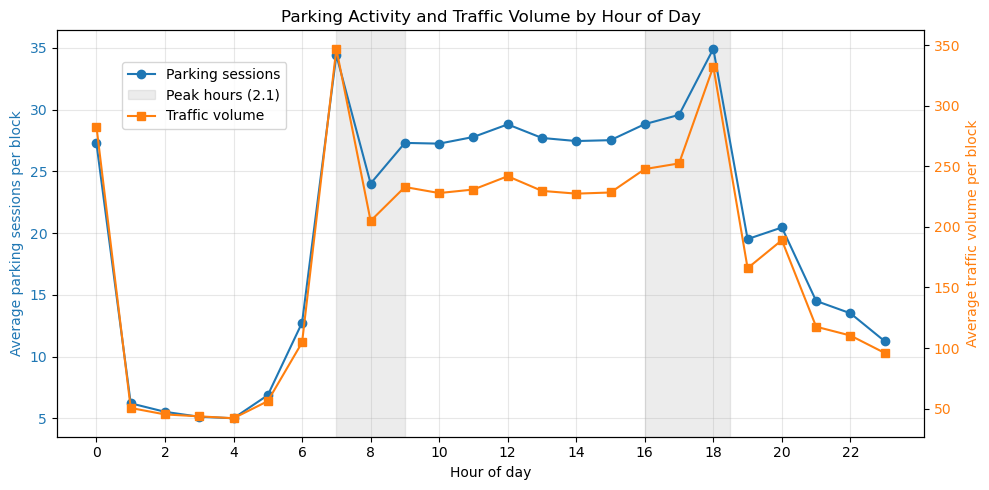

In [37]:
from pyspark.sql.functions import hour

# 2.6 Plot 2: average parking sessions and traffic volume per hour
plot2_data = (
    matched_blocks
    .withColumn("Hour", hour("BlockStart"))
    .groupBy("Hour")
    .agg(_round(avg("ParkingSessions"), 2).alias("AvgParkingSessions"),
         _round(avg("TrafficVolume"), 2).alias("AvgTrafficVolume"))
    .orderBy("Hour")
)

print(f"Row count: {plot2_data.count()}")
plot2_data.show(5, truncate=False)

pdf2 = plot2_data.toPandas()

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(pdf2["Hour"], pdf2["AvgParkingSessions"],
         marker="o", color="tab:blue", label="Parking sessions")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Average parking sessions per block", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.set_xticks(range(0, 24, 2))

# Second axis because the two measures are on different scales
ax2 = ax1.twinx()
ax2.plot(pdf2["Hour"], pdf2["AvgTrafficVolume"],
         marker="s", color="tab:orange", label="Traffic volume")
ax2.set_ylabel("Average traffic volume per block", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")

# Shade the peak periods defined in 2.1
ax1.axvspan(7, 9, alpha=0.15, color="grey")
ax1.axvspan(16, 18.5, alpha=0.15, color="grey", label="Peak hours (2.1)")

ax1.set_title("Parking Activity and Traffic Volume by Hour of Day")
ax1.grid(alpha=0.3)
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()

**Observed pattern.** The two measures follow almost the same daily shape, rising and falling together, which supports the finding in 2.5 that 23.8% of matched blocks are above average on both measures. Activity is concentrated in two narrow spikes at 07:00 and 18:00 rather than spread across the shaded peak windows: at 07:00 both series reach their maximum and then drop sharply by 08:00, and the same happens after 18:00. Between 09:00 and 15:00 both stay on a stable plateau. The spikes align with the start and end of typical restriction periods, suggesting drivers respond to when paid or time-limited parking begins and ends.

One value does not fit the pattern: hour 0 averages 27.27 parking sessions and 282.84 traffic volume, four to five times the values at 01:00 and higher than most of the day. This matches the three `00:00:00` blocks in the 2.5.3 top ten and suggests midnight is acting as a default timestamp for some records rather than reflecting real overnight activity.

**Limitation.** Averaging over hour of day combines weekdays and weekends, so the commuter pattern and weekend behaviour are mixed into one curve; the real weekday peaks are likely sharper than shown. The midnight anomaly also inflates the hour-0 average, so this point should not be read as genuine activity.

## Part 3 Query Optimisation (25%) <a class="anchor" name="part-3"></a>
Assume that the following monthly parking report will be generated regularly. A correct query is required first, but it should also execute efficiently on the full dataset. In this section, implement the report, inspect how Spark executes it, and evaluate the optimization.


Monthly parking report  
For each month, identify the five areas with the highest number of peak-hour parking sessions among areas whose peak-hour violation rate is greater than the monthly violation benchmark.  
Area Violation Rate = (Peak-hour sessions where inViolation is true) / (Peak-hour sessions with a valid inViolation value) * 100   
Monthly Violation Benchmark = (Peak-hour sessions where InViolation is true across all areas in the month) / (Peak-hour sessions with a valid InViolation value across all areas in the same month) * 100  
  
Display:  
- month;
- area id;
- area name;
- park session count;
- violation count;
- violation rate;
- monthly rank.  
Report the number of months and total result rows, Display the complete result ordered by Month and Monthly Rank in ascending order.

##### 3.1 DataFrame API and Spark SQL 
Implement the monthly report independently using:  
1. the PySpark DataFrame API;
2. Spark SQL  
Both implementations must begin with the same prepared input data. Do not create the SQL result by registering the completed DataFrame API result as a temporary view.  
  
Complete the following:  
1. Report the row count returned by each implementation
2. Confirm that the results are identical using exceptAll() in both directions, and display both mismatch counts.
3. For each implementation, display the first 20 result rows using the following column order: 
- Month
- AreaId
- AreaName
- PeakSessionCount
- ViolationCount
- ViolationRate
- MonthlyViolationBenchmark
- MonthlyRank
4. Order the displayed results by Month and MonthlyRank in ascending order.
5. Inspect the physical plan for each implementation, and briefly compare the operations. Briefly explain whether Spark selected different execution strategies, and why?


In [38]:
from pyspark.sql.functions import (
    col, when, sum as _sum, count, round as _round,
    date_format, row_number, lit
)
from pyspark.sql.window import Window

# Peak-hour valid sessions only; InViolation nulls are kept so each
# implementation applies the rate denominator itself
report_input = (
    parking_joined
    .filter(col("HasValidArrival") & col("AreaId").isNotNull() & col("isPeak"))
    .select(
        date_format(col("ArrivalTime"), "yyyy-MM").alias("Month"),
        col("AreaId"),
        col("AreaName"),
        col("InViolation"),
    )
)

# The view exposes the input, not a computed result
report_input.createOrReplaceTempView("report_input")

print("Prepared input sample:")
report_input.show(5, truncate=False)

Prepared input sample:
+-------+------+---------+-----------+
|Month  |AreaId|AreaName |InViolation|
+-------+------+---------+-----------+
|2018-11|35    |Docklands|false      |
|2018-01|35    |Docklands|false      |
|2018-05|35    |Docklands|false      |
|2018-06|35    |Docklands|false      |
|2018-02|35    |Docklands|false      |
+-------+------+---------+-----------+
only showing top 5 rows


In [39]:
# 3.1.1 DataFrame API Implementation
# Step 1: aggregate per month and area
area_month = (
    report_input
    .groupBy("Month", "AreaId", "AreaName")
    .agg(
        count("*").alias("PeakSessionCount"),
        _sum(when(col("InViolation"), 1).otherwise(0))
            .alias("ViolationCount"),
        # Denominator counts only sessions with a non-null InViolation
        _sum(when(col("InViolation").isNotNull(), 1).otherwise(0))
            .alias("ViolationBase"),
    )
)

# Step 2: monthly benchmark via a window, avoiding a second aggregation and join The benchmark sums first and then divides, rather than averaging area rates
month_window = Window.partitionBy("Month")

df_report = (
    area_month
    .withColumn("_MonthViolations", _sum("ViolationCount").over(month_window))
    .withColumn("_MonthBase",       _sum("ViolationBase").over(month_window))
    .withColumn("ViolationRate",
        when(col("ViolationBase") > 0,
             _round(col("ViolationCount") * 100.0 / col("ViolationBase"), 2)))
    .withColumn("MonthlyViolationBenchmark",
        when(col("_MonthBase") > 0,
             _round(col("_MonthViolations") * 100.0 / col("_MonthBase"), 2)))
)

# Step 3: keep areas above the benchmark, then rank within each month
# row_number() guarantees exactly five rows per month; rank() could return more
rank_window = Window.partitionBy("Month").orderBy(
    col("PeakSessionCount").desc(), col("AreaId").asc()
)

df_report = (
    df_report
    .filter(col("ViolationRate") > col("MonthlyViolationBenchmark"))
    .withColumn("MonthlyRank", row_number().over(rank_window))
    .filter(col("MonthlyRank") <= 5)
    .select(
        "Month", "AreaId", "AreaName", "PeakSessionCount",
        "ViolationCount", "ViolationRate",
        "MonthlyViolationBenchmark", "MonthlyRank"
    )
    .orderBy(col("Month").asc(), col("MonthlyRank").asc())
)

print(f"DataFrame API row count: {df_report.count()}")
df_report.show(20, truncate=False)

DataFrame API row count: 120
+-------+------+---------------+----------------+--------------+-------------+-------------------------+-----------+
|Month  |AreaId|AreaName       |PeakSessionCount|ViolationCount|ViolationRate|MonthlyViolationBenchmark|MonthlyRank|
+-------+------+---------------+----------------+--------------+-------------+-------------------------+-----------+
|2018-01|35    |Docklands      |85792           |5606          |6.53         |5.34                     |1          |
|2018-01|38    |Southbank      |45155           |2470          |5.47         |5.34                     |2          |
|2018-01|6     |Titles         |19818           |1115          |5.63         |5.34                     |3          |
|2018-01|13    |Princes Theatre|17223           |1252          |7.27         |5.34                     |4          |
|2018-01|20    |Courtney       |12275           |1605          |13.08        |5.34                     |5          |
|2018-02|35    |Docklands      |804

In [40]:
# 3.1.2 Spark SQL Implementation
# Computed independently from the same input view, not from the API result
sql_report = spark.sql("""
    WITH area_month AS (
        SELECT
            Month,
            AreaId,
            AreaName,
            COUNT(*)                                            AS PeakSessionCount,
            SUM(CASE WHEN InViolation = true THEN 1 ELSE 0 END) AS ViolationCount,
            SUM(CASE WHEN InViolation IS NOT NULL THEN 1 ELSE 0 END) AS ViolationBase
        FROM report_input
        GROUP BY Month, AreaId, AreaName
    ),
    with_benchmark AS (
        SELECT
            Month,
            AreaId,
            AreaName,
            PeakSessionCount,
            ViolationCount,
            ROUND(ViolationCount * 100.0 / NULLIF(ViolationBase, 0), 2) AS ViolationRate,
            ROUND(
                SUM(ViolationCount) OVER (PARTITION BY Month) * 100.0
                / NULLIF(SUM(ViolationBase) OVER (PARTITION BY Month), 0), 2
            ) AS MonthlyViolationBenchmark
        FROM area_month
    ),
    ranked AS (
        -- WHERE applies before ROW_NUMBER, so ranks are contiguous
        SELECT
            *,
            ROW_NUMBER() OVER (
                PARTITION BY Month
                ORDER BY PeakSessionCount DESC, AreaId ASC
            ) AS MonthlyRank
        FROM with_benchmark
        WHERE ViolationRate > MonthlyViolationBenchmark
    )
    SELECT
        Month, AreaId, AreaName, PeakSessionCount,
        ViolationCount, ViolationRate,
        MonthlyViolationBenchmark, MonthlyRank
    FROM ranked
    WHERE MonthlyRank <= 5
    ORDER BY Month ASC, MonthlyRank ASC
""")

print(f"Spark SQL row count: {sql_report.count()}")
sql_report.show(20, truncate=False)

Spark SQL row count: 120
+-------+------+---------------+----------------+--------------+-------------+-------------------------+-----------+
|Month  |AreaId|AreaName       |PeakSessionCount|ViolationCount|ViolationRate|MonthlyViolationBenchmark|MonthlyRank|
+-------+------+---------------+----------------+--------------+-------------+-------------------------+-----------+
|2018-01|35    |Docklands      |85792           |5606          |6.53         |5.34                     |1          |
|2018-01|38    |Southbank      |45155           |2470          |5.47         |5.34                     |2          |
|2018-01|6     |Titles         |19818           |1115          |5.63         |5.34                     |3          |
|2018-01|13    |Princes Theatre|17223           |1252          |7.27         |5.34                     |4          |
|2018-01|20    |Courtney       |12275           |1605          |13.08        |5.34                     |5          |
|2018-02|35    |Docklands      |80425  

In [41]:
# 3.1.3 Row Counts, Verification and Results (requirements 1-4)
df_count  = df_report.count()
sql_count = sql_report.count()

print(f"DataFrame API row count : {df_count:,}")
print(f"Spark SQL row count     : {sql_count:,}")

# Both directions are needed: one alone cannot detect extra rows on the other side
diff_df_minus_sql = df_report.exceptAll(sql_report).count()
diff_sql_minus_df = sql_report.exceptAll(df_report).count()

print(f"\nMismatch (DataFrame - SQL) : {diff_df_minus_sql}")
print(f"Mismatch (SQL - DataFrame) : {diff_sql_minus_df}")
print("Results identical." if (diff_df_minus_sql == 0 and diff_sql_minus_df == 0)
      else "WARNING: results differ.")

print(f"\nNumber of months : {df_report.select('Month').distinct().count()}")
print(f"Total result rows: {df_count:,}")

print("\n--- DataFrame API: first 20 rows ---")
df_report.show(20, truncate=False)

print("--- Spark SQL: first 20 rows ---")
sql_report.show(20, truncate=False)

DataFrame API row count : 120
Spark SQL row count     : 120

Mismatch (DataFrame - SQL) : 0
Mismatch (SQL - DataFrame) : 0
Results identical.

Number of months : 24
Total result rows: 120

--- DataFrame API: first 20 rows ---
+-------+------+---------------+----------------+--------------+-------------+-------------------------+-----------+
|Month  |AreaId|AreaName       |PeakSessionCount|ViolationCount|ViolationRate|MonthlyViolationBenchmark|MonthlyRank|
+-------+------+---------------+----------------+--------------+-------------+-------------------------+-----------+
|2018-01|35    |Docklands      |85792           |5606          |6.53         |5.34                     |1          |
|2018-01|38    |Southbank      |45155           |2470          |5.47         |5.34                     |2          |
|2018-01|6     |Titles         |19818           |1115          |5.63         |5.34                     |3          |
|2018-01|13    |Princes Theatre|17223           |1252          |7.27    

In [42]:
# 3.1.5 Compare the physical plans of both implementations
print("DataFrame API - Physical Plan")
df_report.explain(mode="formatted")

print("\nSpark SQL - Physical Plan")
sql_report.explain(mode="formatted")

DataFrame API - Physical Plan
== Physical Plan ==
AdaptiveSparkPlan (35)
+- Sort (34)
   +- Exchange (33)
      +- Filter (32)
         +- Window (31)
            +- WindowGroupLimit (30)
               +- Sort (29)
                  +- Project (28)
                     +- Filter (27)
                        +- Window (26)
                           +- Sort (25)
                              +- Exchange (24)
                                 +- HashAggregate (23)
                                    +- Exchange (22)
                                       +- HashAggregate (21)
                                          +- Project (20)
                                             +- BroadcastHashJoin LeftOuter BuildRight (19)
                                                :- Project (11)
                                                :  +- BroadcastHashJoin LeftOuter BuildRight (10)
                                                :     :- Project (3)
                                      

**Comparison.** The two plans are effectively identical. Both scan the CSV with the peak-hour filter pushed into the `Filter` operator, broadcast the two lookup tables, aggregate with a partial/final `HashAggregate` pair around `Exchange hashpartitioning(Month, AreaId, AreaName, 200)`, then repartition by `Month` for two `Window` operators — one for the monthly benchmark and one for the ranking — before a final `Exchange rangepartitioning` and `Sort`. Both also apply `WindowGroupLimit`, an optimisation that keeps only the top five rows per month before the full ranking is computed. The only structural difference is that the SQL plan evaluates `ViolationRate` in a `Project` before the second exchange (node 24), whereas the API plan computes it after the window; the API plan has 35 nodes and the SQL plan 36.

**Why.** Spark did not select different execution strategies. The DataFrame API and Spark SQL are two front-ends to the same Catalyst optimiser: both are parsed into the same logical plan, rewritten by the same rules, and compiled into the same physical operators. The minor differences reflect how each expression was written rather than a different strategy — the SQL literal `100.0` is treated as a decimal while the Python `100.0` is a double, but rounding to two decimal places makes the results identical, as confirmed by `exceptAll()` returning zero in both directions.

##### 3.2 Baseline plan and Spark UI analysis  
Select either SQL or DataFrame API from Section 3.1 as a baseline. Clearly state which implementation you selected.  
Before running the baseline query, set: sc.setJobDescription(f"A1-P3-2-Baseline-{student_auth_code}")  
Execute an action that materialises the complete final result and record the wall-clock execution time. Use the same action later when evaluating the optimised query.  
Submit and include:  
- the formatted physical plan, you may refer to the plan already printed in Section 3.1 rather than printing it again.
- Spark UI screenshots clearly showing: the job description, the SQL/DAG, the relevant stage details, relevant shuffle-read, shuffle-write figures, where applicable.
- the measured execution time;  
In no more than 300 words:  
1. Identify the most expensive stages or operations.
2. Support the explanation using numbers visible in your screenshots.
3. Suggest an improvement strategy.


**Baseline selected: the DataFrame API implementation.** Section 3.1.4 showed that both implementations compile to the same physical plan, so either could serve as the baseline. The DataFrame API is chosen because the optimisation in 3.3 is easier to apply programmatically.

In [43]:
import time

# 3.2 Baseline: the DataFrame API implementation from 3.1.1
sc.setJobDescription(f"A1-P3-2-Baseline-{student_auth_code}")

t0 = time.time()
baseline_rows = df_report.collect()
baseline_time = time.time() - t0

sc.setJobDescription(None)

print(f"Baseline rows materialised: {len(baseline_rows):,}")
print(f"Baseline wall-clock time  : {baseline_time:.2f} seconds")

Baseline rows materialised: 120
Baseline wall-clock time  : 360.97 seconds


#### 3.2 Baseline Plan and Spark UI Analysis

**Baseline selected: the DataFrame API implementation (3.1.1).** Section 3.1.4 showed that both implementations compile to essentially the same physical plan, so either could serve as the baseline; the DataFrame API is chosen because the optimisation in 3.3 is easier to apply programmatically. The formatted physical plan is the DataFrame API plan printed in Section 3.1.4 and is not repeated here.

**Measured execution time: 360.97 seconds** for `collect()` materialising all 120 result rows.

**(a) Jobs tab with job description `A1-P3-2-Baseline-ylii0798`**

![Jobs](screenshot/p3_baseline_jobs.png)

**(b) SQL tab: query duration 5.4 min**

![SQL](screenshot/p3_baseline_sql.png)

**(c) Query DAG**

![DAG](screenshot/p3_baseline_dag.png)

**(d) Stage 92: 8.6 GiB input, 1057.9 KiB shuffle write, 69 tasks**

![Stage](screenshot/p3_baseline_stage.png)

---

**Most expensive operation.** The cost is dominated by a single stage. Stage 92 reads the full 8.6 GiB CSV across 69 tasks and runs for 5.4 minutes, which is effectively the entire 360.97-second wall-clock time of the query. Every other stage completes in seconds.

**Evidence.** The stage detail shows 8.6 GiB of input but only 1057.9 KiB of shuffle write — a reduction of roughly 8,500 times. The peak-hour filter and the `partial_count` / `partial_sum` aggregations both run before the exchange, so only a few thousand per-month, per-area rows cross the network. The later stages, which perform the two `Window` operations for the monthly benchmark and the ranking, therefore operate on about 1 MB of data and are negligible. The three `Exchange` operators visible in the DAG are not the bottleneck: shuffling is cheap here, scanning is not. The scan is also expensive beyond its size, because the `Filter` node applies `try_to_timestamp` to the raw `ArrivalTime` string of all 72.9 million records before the peak-hour condition can be evaluated.

**Improvement strategy.** Since the report is intended to run regularly, the repeated cost of parsing the raw CSV should be eliminated. Writing the cleaned, peak-hour input to Parquet once and reading the report from that file would avoid re-scanning and re-parsing 8.6 GiB on every run. Parquet is columnar and stores already-parsed types, so only the four columns the report needs would be read and the timestamp conversion would not be repeated. This directly targets the stage that accounts for essentially all of the measured runtime.

##### 3.3 Evaluate one optimisation  
Implement one optimisation based on the evidence and reasoning presented in Section 3.2. Briefly state what you changed and why you expect it to improve execution.  
Before executing it, set: sc.setJobDescription(f"A1-P3-3-Optimised-{student_auth_code}")  
Then:  
1. Run the baseline and revised queries under the same conditions;
2. Confirm that the optimised query produces exactly the same result as the baseline
3. Record the execution time and collect the corresponding Spark UI evidence.
4. Decide whether the optimisation should be retained, justify your decision.
5. A technically reasonable improvement and evidence-based evaluation are required for full marks.


### 3.3 Evaluate One Optimisation

**What was changed:** The prepared input is written once to Parquet, and the report reads from that file instead of re-scanning the raw CSV.

**Why:** Section 3.2 showed that a single stage reading 8.6 GiB accounts for essentially the whole 360.97-second runtime, while shuffle write is only 1057.9 KiB. The bottleneck is therefore the scan, not data movement. Parquet stores only the four columns the report needs, in compressed columnar form with the timestamps already parsed, so each run avoids both re-reading 8.6 GiB and re-applying `try_to_timestamp` to 72.9 million records.

In [44]:
import time

# 3.3 Optimisation: persist the prepared input as Parquet Baseline re-scans and re-parses 8.6 GiB of CSV on every run
PARQUET_PATH = "/home/student/A1/report_input_parquet"

t0 = time.time()
report_input.write.mode("overwrite").parquet(PARQUET_PATH)
write_time = time.time() - t0

print(f"Parquet write time: {write_time:.2f} seconds")

Parquet write time: 387.98 seconds


In [45]:
# Same logic as 3.1.1; only the source changed from CSV to Parquet
report_input_opt = spark.read.parquet(PARQUET_PATH)

area_month_opt = (
    report_input_opt
    .groupBy("Month", "AreaId", "AreaName")
    .agg(
        count("*").alias("PeakSessionCount"),
        _sum(when(col("InViolation"), 1).otherwise(0)).alias("ViolationCount"),
        _sum(when(col("InViolation").isNotNull(), 1).otherwise(0)).alias("ViolationBase"),
    )
)

opt_report = (
    area_month_opt
    .withColumn("_MonthViolations", _sum("ViolationCount").over(month_window))
    .withColumn("_MonthBase",       _sum("ViolationBase").over(month_window))
    .withColumn("ViolationRate",
        when(col("ViolationBase") > 0,
             _round(col("ViolationCount") * 100.0 / col("ViolationBase"), 2)))
    .withColumn("MonthlyViolationBenchmark",
        when(col("_MonthBase") > 0,
             _round(col("_MonthViolations") * 100.0 / col("_MonthBase"), 2)))
    .filter(col("ViolationRate") > col("MonthlyViolationBenchmark"))
    .withColumn("MonthlyRank", row_number().over(rank_window))
    .filter(col("MonthlyRank") <= 5)
    .select(
        "Month", "AreaId", "AreaName", "PeakSessionCount",
        "ViolationCount", "ViolationRate",
        "MonthlyViolationBenchmark", "MonthlyRank"
    )
    .orderBy(col("Month").asc(), col("MonthlyRank").asc())
)

# Same action as the baseline so the two timings are comparable
sc.setJobDescription(f"A1-P3-3-Optimised-{student_auth_code}")

t0 = time.time()
opt_rows = opt_report.collect()
opt_time = time.time() - t0

sc.setJobDescription(None)

print(f"Optimised rows materialised: {len(opt_rows):,}")
print(f"Optimised wall-clock time  : {opt_time:.2f} seconds")
print(f"Baseline wall-clock time   : {baseline_time:.2f} seconds")
print(f"Speed-up                   : {baseline_time / opt_time:.1f}x")

Optimised rows materialised: 120
Optimised wall-clock time  : 4.95 seconds
Baseline wall-clock time   : 360.97 seconds
Speed-up                   : 72.9x


In [46]:
# Requirement 2: the optimised query must produce exactly the same result
diff_opt_minus_base = opt_report.exceptAll(df_report).count()
diff_base_minus_opt = df_report.exceptAll(opt_report).count()

print(f"Mismatch (optimised - baseline) : {diff_opt_minus_base}")
print(f"Miensmatch (baseline - optimised) : {diff_base_minus_opt}")
print("Results identical." if (diff_opt_minus_base == 0 and diff_base_minus_opt == 0)
      else "WARNING: results differ.")

Mismatch (optimised - baseline) : 0
Mismatch (baseline - optimised) : 0
Results identical.


**(a) Jobs tab: `A1-P3-3-Optimised-ylii0798`, main job 17 s**

![Jobs](screenshot/p3_optimised_jobs.png)

**(b) SQL tab: query duration ~21 s (baseline: 5.4 min)**

![SQL](screenshot/p3_optimised_sql.png)

**(c) Stage 105: 201.5 MiB input across 9 tasks, 1061.2 KiB shuffle write**

![Stage](screenshot/p3_optimised_stage.png)

**Decision: retain the optimisation.**

The optimised query runs in 4.95 seconds against 360.97 seconds for the baseline — a 72.9x speed-up — and returns the identical 120 rows, with `exceptAll()` returning zero in both directions.

The stage-level evidence explains the gain. The baseline stage reads 8.6 GiB across 69 tasks, while the optimised stage reads only 201.5 MiB across 9 tasks. Input volume falls by a factor of about 43, because Parquet stores only the four required columns in compressed columnar form with timestamps already parsed. Crucially, shuffle write is almost unchanged (1057.9 KiB against 1061.2 KiB, under 0.3% difference), confirming the improvement comes entirely from the read path rather than reduced data movement — exactly what the Section 3.2 evidence predicted.

Converting to Parquet costs 387.98 seconds once, slightly more than a single baseline run, so the first execution is marginally slower overall. The break-even point is the second run. Since the report is generated monthly, twelve runs would take about 447 seconds in total with Parquet against 4,332 seconds without it — a 9.7x reduction in cumulative cost.

**Limitation.** Both queries ran sequentially in the same session, so the optimised run may have benefited from operating-system file caching. However, the improvement is accompanied by a 43x reduction in bytes read at stage level, so it is structural rather than an artefact of caching.